# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_:Maribao, Jake AGustin B.
- _Student No._: 2023-08777
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

**Problem 1.** Diffraction limit of a telescope.

<img src="p1_bessel.png" alt="Bessel functions" width=45%> <img src="p1_diffraction.png" alt="Diffraction pattern" width=45%>

_Figure 1. Left: Bessel functions J0, J1 and J2 for x from 0 to 20, computed from their integral form with Simpson's rule (N = 1000). Right: density plot of the diffraction pattern I(r) = (J1(kr)/kr)² of a point source with λ = 500 nm, over a 2 μm × 2 μm square of the focal plane. The color scale saturates at 0.01 (the centre reaches 0.25) so the faint rings are visible._

**Problem 2.** Gamma function by Monte Carlo with importance sampling.

<img src="p2_gamma.png" alt="Gamma function" width=60%>

_Figure 2. Γ(z) for z in [1, 5] from importance-sampled Monte Carlo (red points, 10^6 samples each, error bars of one standard error) and from scipy.special.gamma (black curve). The samples are drawn from p(t) = e^(-t/z)/z. The largest difference is 0.14%._

### Report discussion

**Problem 1. Explain the figure.** The left plot shows J0, J1 and J2 from x = 0 to 20, computed with Simpson's rule (N = 1000) and matching scipy.special.jv to 4×10^-15. J0 starts at 1 while J1 and J2 start at 0, and all three oscillate with a slowly shrinking amplitude. The right plot is the intensity I(r) = (J1(kr)/kr)² of a point source at λ = 500 nm. A bright central disk, the Airy disk, is surrounded by dark rings at the zeros of J1 (kr = 3.83, 7.02 and 10.17), which fall at r = 0.30, 0.56 and 0.81 μm. The first bright ring is only 1.7% as bright as the centre, which is why vmax = 0.01 is needed to see it. Two stars whose images are closer than about this first dark ring (0.30 μm) therefore blur into one, which is the diffraction limit of the telescope.

**Problem 2. What is the difference between this version of Monte Carlo and the one we did in the previous session?** In the previous session we used hit-or-miss Monte Carlo, where points were spread uniformly over a finite box and the area came from the fraction that fell under the curve. Here we use mean-value Monte Carlo with importance sampling. Points t are drawn from a probability density p(t) = e^(-t/z)/z that follows the integrand, and the integral is the average of g(t) = f(t)/p(t). This handles the infinite upper limit of Γ(z), which no finite box can cover, and puts the samples where t^(z-1) e^(-t) is large. With 10^6 points per z, the estimate agreed with scipy.special.gamma to within 0.14% for every z in [1, 5], and at z = 1 it is exact because g is constant.

**What should we be careful of when applying Monte Carlo with importance sampling?** The density p must be normalized, must be positive wherever f is nonzero, and the samples must truly follow p, which here comes from the inverse transform t = -z ln(1 - u). Most importantly, p needs a tail at least as heavy as f. Otherwise g = f/p blows up where p is small and its variance becomes infinite. At z = 5, p = e^(-t/z)/z gave errors below 0.1% and p = e^(-t) gave about 1%. p = 2e^(-2t), whose tail falls faster than f, gave errors from 4% to 21%, and its own standard-error estimate did not match the actual error. The best p has nearly the shape of f so that g is almost constant, but the perfect choice f/Γ(z) would need the very answer we are computing.

### Other comments
- `J(m, x)` loops over the 1001 Simpson nodes instead of building a 1001 × N array, which keeps memory small for the 251 × 251 grid of the density plot.
- Among exponential densities p(t) = λe^(-λt), the variance of g is smallest at λ = 1/z. That puts the mean of p at z, close to the peak of the integrand at t = z - 1.
- The error bars in Figure 2 are smaller than the markers, since the standard error is below 0.1% of Γ(z).
- Reflection: the importance-sampling comparison showed that a bad p can fail quietly. The estimate still looks like a number, and only its spread over several seeds reveals the problem.

---
## Section 2: Code

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import special

### Problem 1: Diffraction limit of a telescope

![Screenshot 2026-11-09 at 5.08.50 PM.png](DiffLimitTelescopeNeumann5-4.png)


Hint 1: You may find it useful to know that $\lim_{x→0} J_1(x)/x = 1/2$ 

Hint 2: The central
spot in the diffraction pattern is so bright that it may be difficult to see the rings around
it on the computer screen. If you run into this problem a simple way to deal with it is to
use one of the other color schemes for density plots described in Section 3.3. The “hot”
scheme works well. For a more sophisticated solution to the problem, the imshow function has an additional argument vmax that allows you to set the value that corresponds
to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in x with value 0.1, or any greater value, will produce the brightest (most positive) color on the screen. By lowering the `vmax` value, you can reduce the total range of
values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. (There is also a `vmin` argument that can
be used to set the value that corresponds to the dimmest (most negative) color.) For this
exercise a value of `vmax=0.01` appears to work well.

### Approach.

- The Bessel Function is computed from its integral form $J_m(x) = \frac{1}{\pi}\int_0^\pi \cos(m\theta - x\sin\theta)\,d\theta$ with Simpson's Rule and N = 100 slices. The nodes and weights are built once and reused.
- `J(m, x)` accepts arrays, so the whole 251 × 251 grid of kr values is evaluated in one call. It is checked against `scipy.special.jv`.
- The intensity $I(r) = \left(J_1(kr)/kr\right)^2$ uses the limit $J_1(x)/x \to 1/2$ at the center so, $I(0) = 1/4$ without dividing by zero.
- `imshow` with the `hot` colormap and `vmax = 0.01` makes the faint rings visible next to the bright center.

In [7]:
def simpson_nodes(a, b, N):
    """Nodes and Simpson's 1/3 weights for N slices (N even) on [a, b]."""
    h = (b - a)/N
    w = np.full(N + 1, 2*h/3)
    w[1::2] = 4*h/3                          # weights h/3 * (1, 4, 2, 4, ..., 4, 1)
    w[[0, -1]] = h/3
    return np.linspace(a, b, N + 1), w

THETA, W = simpson_nodes(0, np.pi, 1000)     # N = 1000 slices, computed once and reused by every call


def J(m, x):
    """Bessel function J_m(x) = (1/π) ∫_0^π cos(mθ - x sin θ) dθ by Simpson's rule. x may be a scalar or an array."""
    x = np.asarray(x, dtype=float)
    total = np.zeros_like(x)
    for theta, w in zip(THETA, W):           # loop over the 1001 nodes, so memory stays the size of x
        total += w*np.cos(m*theta - x*np.sin(theta))
    return total/np.pi


x = np.linspace(0, 20, 401)
for m in range(3):
    print(f'max |J_{m} - scipy.special.jv| on [0, 20] = {np.abs(J(m, x) - special.jv(m, x)).max():.1e}')

max |J_0 - scipy.special.jv| on [0, 20] = 4.2e-15
max |J_1 - scipy.special.jv| on [0, 20] = 1.2e-15
max |J_2 - scipy.special.jv| on [0, 20] = 1.2e-15


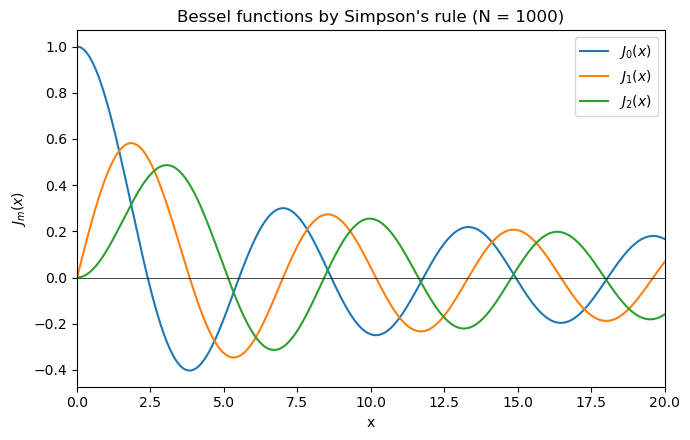

In [8]:
# (a) J0, J1 and J2 on a single graph
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in range(3):
    ax.plot(x, J(m, x), label=f'$J_{m}(x)$')
ax.axhline(0, color='k', lw=0.5)
ax.set(xlim=(0, 20), xlabel='x', ylabel='$J_m(x)$', title="Bessel functions by Simpson's rule (N = 1000)")
ax.legend()
fig.tight_layout()
fig.savefig('p1_bessel.png', dpi=120)
plt.show() 

In [37]:
#for notes
plt.imshow?

Signature:
plt.imshow(
    X: 'ArrayLike | PIL.Image.Image',
    cmap: 'str | Colormap | None' = None,
    norm: 'str | Normalize | None' = None,
    *,
    aspect: "Literal['equal', 'auto'] | float | None" = None,
    interpolation: 'str | None' = None,
    alpha: 'float | ArrayLike | None' = None,
    vmin: 'float | None' = None,
    vmax: 'float | None' = None,
    origin: "Literal['upper', 'lower'] | None" = None,
    extent: 'tuple[float, float, float, float] | None' = None,
    interpolation_stage: "Literal['data', 'rgba'] | None" = None,
    filternorm: 'bool' = True,
    filterrad: 'float' = 4.0,
    resample: 'bool | None' = None,
    url: 'str | None' = None,
    data=None,
    **kwargs,
) -> 'AxesImage'
Docstring:
Display data as an image, i.e., on a 2D regular raster.

The input may either be actual RGB(A) data, or 2D scalar data, which
will be rendered as a pseudocolor image. For displaying a grayscale
image, set up the colormapping using the parameters
``cmap='gray', vmin

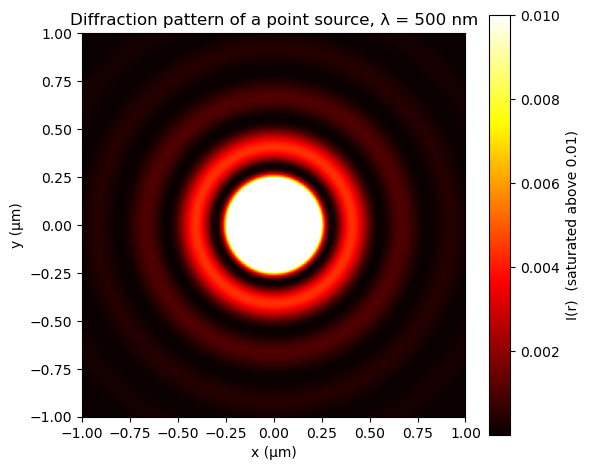

dark rings (zeros of J1) at r = 0.305, 0.558, 0.810 μm
brightest point I(0) = 0.25


In [13]:
# (b) Density plot of the diffraction pattern I(r) = (J1(kr)/kr)^2 of a point source
wavelength = 0.5                             # λ = 500 nm, written in μm
k = 2*np.pi/wavelength                       # wavenumber (1/μm)
side = np.linspace(-1, 1, 251)               # square region of the focal plane, r up to 1 μm along the axes (μm)
X, Y = np.meshgrid(side, side)
kr = k*np.hypot(X, Y)

safe_kr = np.where(kr == 0, 1, kr)           # avoid 0/0 at the centre
I = np.where(kr == 0, 0.25, (J(1, kr)/safe_kr)**2)   # lim J1(x)/x = 1/2 as x -> 0, so I(0) = 1/4

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(I, extent=(-1, 1, -1, 1), origin='lower', cmap='hot', vmax=0.01)   # vmax brings out the faint rings
fig.colorbar(im, ax=ax, label='I(r)  (saturated above 0.01)')
ax.set(xlabel='x (μm)', ylabel='y (μm)', title='Diffraction pattern of a point source, λ = 500 nm')
fig.tight_layout()
fig.savefig('p1_diffraction.png', dpi=120)
plt.show()

print('dark rings (zeros of J1) at r =', ', '.join(f'{s/k:.3f}' for s in special.jn_zeros(1, 3)), 'μm')
print(f'brightest point I(0) = {I.max():.2f}')

Report discussion: Explain the figure

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [1,5]$ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$. Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$

### Approach.

- The integrand is $f(t) = t^{z - 1}e^{-t}$.
- Samples are drawn from the exponential identity $p(t) = \frac{1}{z}e^{-t/z}$ on $[0, \infty)$, which covers the infinite domain and has its mean at z, near the peak of f at t = z - 1.
- Samples come from the inverse transform $t = -z/ln(1 - u)$ with $u$ uniform on $[0, 1)$.
- $\Gamma(z) \approx \frac{1}{n}\sum g(t_i)$ with $g = f/p = z\, t^{z - 1}e^{-t(1-1/z)}$, and the standard error is the sample standard deviation of g divided by $\sqrt{N}$.

In [15]:
def gamma_mc(z, N, rng, rate=None):
    """Γ(z) = ∫_0^∞ t^(z-1) e^(-t) dt by Monte Carlo with importance sampling.

    Samples t from p(t) = rate * e^(-rate t) (default rate = 1/z) and averages g = f/p.
    Returns (estimate, standard error).
    """
    if rate is None:
        rate = 1/z
    t = -np.log(1 - rng.random(N))/rate                      # inverse transform: u ~ U[0, 1) gives t ~ p(t)
    g = t**(z - 1)*np.exp(-t)/(rate*np.exp(-rate*t))         # g = f/p
    return g.mean(), g.std(ddof=1)/np.sqrt(N)


rng = np.random.default_rng(0)
N = 10**6                                                    # samples for each z
z_vals = np.linspace(1, 5, 41)
results = np.array([gamma_mc(z, N, rng) for z in z_vals])
gamma_est, gamma_err = results.T

rel_err = np.abs(gamma_est/special.gamma(z_vals) - 1)
print(f'largest relative error vs scipy.special.gamma: {rel_err.max():.2%} (at z = {z_vals[rel_err.argmax()]:.1f})')
print(f'Γ(1) estimate = {gamma_est[0]:.12f} (g = 1 exactly when z = 1)')

largest relative error vs scipy.special.gamma: 0.14% (at z = 4.1)
Γ(1) estimate = 1.000000000000 (g = 1 exactly when z = 1)


In [36]:
#for notes
plt.plot?

Signature:
plt.plot(
    *args: 'float | ArrayLike | str',
    scalex: 'bool' = True,
    scaley: 'bool' = True,
    data=None,
    **kwargs,
) -> 'list[Line2D]'
Docstring:
Plot y versus x as lines and/or markers.

Call signatures::

    plot([x], y, [fmt], *, data=None, **kwargs)
    plot([x], y, [fmt], [x2], y2, [fmt2], ..., **kwargs)

The coordinates of the points or line nodes are given by *x*, *y*.

The optional parameter *fmt* is a convenient way for defining basic
formatting like color, marker and linestyle. It's a shortcut string
notation described in the *Notes* section below.

>>> plot(x, y)        # plot x and y using default line style and color
>>> plot(x, y, 'bo')  # plot x and y using blue circle markers
>>> plot(y)           # plot y using x as index array 0..N-1
>>> plot(y, 'r+')     # ditto, but with red plusses

You can use `.Line2D` properties as keyword arguments for more
control on the appearance. Line properties and *fmt* can be mixed.
The following two calls yie

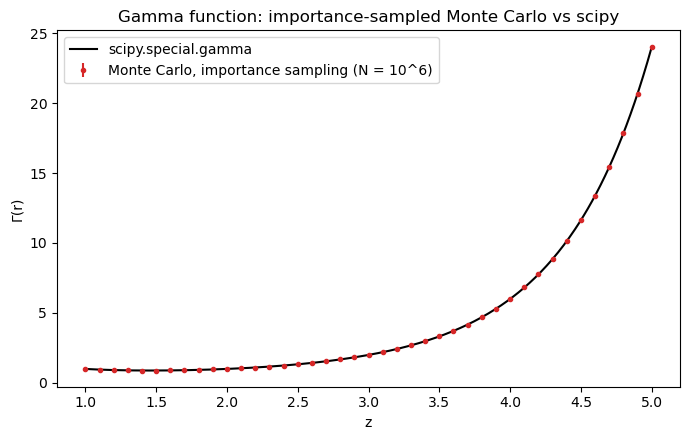

In [24]:
z_fine = np.linspace(1, 5, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(z_fine, special.gamma(z_fine), 'k', label = 'scipy.special.gamma')
ax.errorbar(z_vals, gamma_est, yerr=gamma_err, fmt='oC3', ms=3, label='Monte Carlo, importance sampling (N = 10^6)') 
ax.set(xlabel='z', ylabel='Γ(r)', title='Gamma function: importance-sampled Monte Carlo vs scipy')
ax.legend()
fig.tight_layout()
fig.savefig('p2_gamma.png', dpi=120)
plt.show()


Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

### Choice of p(t)

The same estimator at z = 5 with three exponential densities. Rate 2 has a tail that falls faster than $f(t) \sim t^4 e^{-t}$, so g = f/p grows without bound and its variance is infinite.

In [27]:
z = 5
print(f'Γ(5) = {special.gamma(z):.0f}, N = 10^6 samples, 3 seeds each')
for rate, name in ((1/z, 'p = e^(-t/z)/z  rate(1/z)'), (1, 'p = e^(-t)  (rate 1)'), (2, 'p = 2e^(-2t)    (rate 2)  ')):
    for seed in range(3):
        est, err = gamma_mc(z, N, np.random.default_rng(seed), rate)
        print(f'{name}  seed {seed}: estimate {est:8.4f}   actual error {abs(est/24 - 1):6.2%}   reported std error {err/24:6.2%}')

Γ(5) = 24, N = 10^6 samples, 3 seeds each
p = e^(-t/z)/z  rate(1/z)  seed 0: estimate  23.9864   actual error  0.06%   reported std error  0.09%
p = e^(-t/z)/z  rate(1/z)  seed 1: estimate  23.9828   actual error  0.07%   reported std error  0.09%
p = e^(-t/z)/z  rate(1/z)  seed 2: estimate  23.9968   actual error  0.01%   reported std error  0.09%
p = e^(-t)  (rate 1)  seed 0: estimate  24.2301   actual error  0.96%   reported std error  0.84%
p = e^(-t)  (rate 1)  seed 1: estimate  23.7808   actual error  0.91%   reported std error  0.83%
p = e^(-t)  (rate 1)  seed 2: estimate  23.6796   actual error  1.34%   reported std error  0.78%
p = 2e^(-2t)    (rate 2)    seed 0: estimate  24.9143   actual error  3.81%   reported std error 25.31%
p = 2e^(-2t)    (rate 2)    seed 1: estimate  25.1682   actual error  4.87%   reported std error 23.92%
p = 2e^(-2t)    (rate 2)    seed 2: estimate  19.0012   actual error 20.83%   reported std error  7.50%
